# Archives and verified extraction

Archive two known files, restore into a new temporary destination and check the restored bytes.

Each path used for archiving is relative to the fixture root. The extraction directory starts empty. This lab handles an archive just created from known inputs.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
mkdir input restored
printf %s one > input/first
printf %s second > input/next
(cd input && tar -cf ../example.tar first next)
(cd restored && tar -xf ../example.tar)
for name in first next; do
    cmp "input/$name" "restored/$name"
    wc -c < "restored/$name"
done
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [3, 6]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [3, 6]
bash [3, 6]
zsh [3, 6]


## Inspect the outcome

A list of archive member names establishes inventory. Comparing the extracted files tests the contents directly.

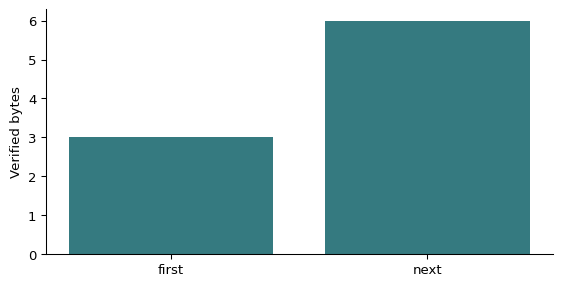

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["first", "next"], observed, color="#357a80")
ax.set(ylabel="Verified bytes")
plt.show()

## Interpreting the result

A list of archive member names establishes inventory. Comparing the extracted files tests the contents directly.

## Exercise

Add a file in a subdirectory and carry the same integrity check through the restore.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)